# Effect of the regularization on 2.5D DC resistivity inversion

This notebook compares the four types of regularization available in `pymmr.inversion.Inversion`
for the inversion of synthetic 2.5D DC resistivity data: a conductive block in a homogeneous
background, surveyed with a dipole-dipole array.

The model objective function is $\phi_m = \sum_{i\in\{x,y,z\}} \alpha_i^2 \|W_i^{1/2} G_i m\|^2 + \alpha_s \|W_s^{1/2}(m - m_{ref})\|^2$,
with $m = \ln\sigma$ and $G_i$ the gradient operators. For the non-quadratic measures, the weights $W$ are
updated at each iteration from the current model (iteratively reweighted least squares), with $c = G_i m$:

| `smooth_type` | weight of the squared gradient | effect |
|---|---|---|
| `'smooth'` | $w = 1$ | $L_2$ norm of the gradient: smooth models |
| `'blocky'` | $w \propto 1/|c|$, within $[10^{-6}, 10]$ | $L_1$ norm of the gradient: piecewise constant models, sharp edges |
| `'ekblom'` | $w = p\,(c^2+\epsilon^2)^{p/2-1}$, at most 2 | Ekblom measure $\sum (c^2+\epsilon^2)^{p/2}$; $p=2$ is smooth, $p\to1$ approaches $L_1$ |
| `'min. support'` | $w = \sqrt{2}\,\epsilon/(c^2+\epsilon^2)$, at most 2 (default `minsupport_form='portniaguine'`), or $w = 2\epsilon^2/(c^2+\epsilon^2)^2$ (`'general'`) | minimum gradient support: compact bodies with sharp boundaries |

$p$ is `Inversion.ekblom_p` and $\epsilon$ is `Inversion.minsupport_e`. With `'ekblom'`, the smallness term is weighted the same way, from $m - m_{ref}$, with weights at most `Inversion.ekblom_smallness_max` (2 by default). References: Farquharson & Oldenburg (1998,
GJI 134, 213–227) for the $L_1$ and Ekblom measures, and Portniaguine & Zhdanov (1999, Geophysics 64, 874–887)
for the minimum gradient support.

In [1]:
import os
import sys
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

sys.path.insert(0, os.path.abspath('..'))   # notebook run from the examples directory

import pymmr.finite_volume as fvm
from pymmr.finite_volume import calc_padding
from pymmr.dc import GridDC
from pymmr.inversion import Inversion, DataERT

solver = 'mumps' if fvm.has_mumps else 'superlu'
print('solver:', solver)

solver: mumps


## Model and grid

A 2.5D grid (`GridDC((x, z))`): the conductivity is invariant along $y$ and the profile lies in the plane $y = 0$.
Cells are 1 m in the region of interest, with padding cells on the sides and at depth.
The block (10 Ω·m, 12 m × 6 m, top at 4 m depth) is embedded in a 100 Ω·m background.

grid: 110 x 35 cells, x from -257 to 257 m, z from -237 to 0 m


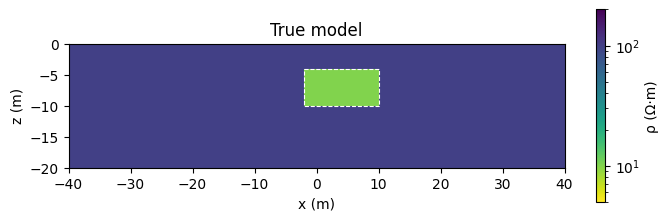

In [2]:
rho_bg, rho_blk = 100.0, 10.0
h = 1.0
x = np.arange(-40., 40.01, h)
z = np.arange(-20., 0.01, h)
pad = np.cumsum(calc_padding(h, 15))
x = np.r_[x[0] - pad[::-1], x, x[-1] + pad]
z = np.r_[z[0] - pad[::-1], z]

g = GridDC((x, z))
xc, _, zc = g.fv.centre_voxels()
block = (np.abs(xc - 4) < 6) & (zc < -4) & (zc > -10)
sigma_true = np.where(block, 1 / rho_blk, 1 / rho_bg)
print(f'grid: {g.fv.nx} x {g.fv.nz} cells, x from {x[0]:.0f} to {x[-1]:.0f} m, z from {z[0]:.0f} to 0 m')

outline = dict(xy=([-2, 10, 10, -2, -2], [-4, -4, -10, -10, -4]))

def plot_model(ax, sigma, title):
    im = ax.pcolormesh(g.fv.x, g.fv.z, (1 / sigma).reshape(g.fv.nz, g.fv.nx),
                       norm=LogNorm(5, 200), cmap='viridis_r')
    ax.plot(*outline['xy'], 'w--', lw=0.8)
    ax.set_xlim(-40, 40)
    ax.set_ylim(-20, 0)
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.set_ylabel('z (m)')
    return im

fig, ax = plt.subplots(figsize=(8, 2.5))
im = plot_model(ax, sigma_true, 'True model')
ax.set_xlabel('x (m)')
fig.colorbar(im, ax=ax, label='ρ (Ω·m)')
plt.show()

## Survey and synthetic data

37 surface electrodes, 2 m apart, dipole-dipole with $a$ = 2, 4 and 6 m and $n$ = 1 to 6 (468 measurements).
Voltages (mV, for 1 A) are computed with the 2.5D forward model and contaminated with 2 % Gaussian noise.

468 measurements


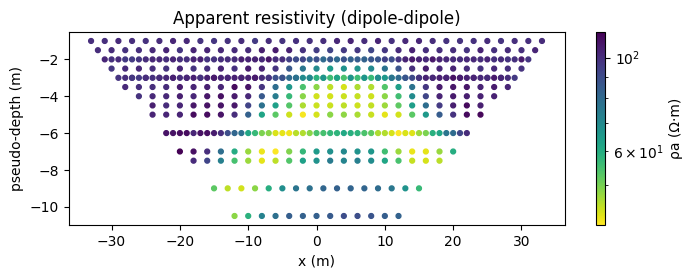

In [3]:
e = np.arange(-36., 36.1, 2.)
rows = np.array([[e[i], e[i + a], e[i + a + n * a], e[i + 2 * a + n * a]]
                 for a in (1, 2, 3) for n in range(1, 7) for i in range(len(e)) if i + 2 * a + n * a < len(e)])
zeros = np.zeros(len(rows))
c1c2 = np.c_[rows[:, 0], zeros, zeros, rows[:, 1], zeros, zeros]
p1p2 = np.c_[rows[:, 2], zeros, zeros, rows[:, 3], zeros, zeros]

g.set_solver(solver)
g.set_survey_ert(c1c2, p1p2, cs=1.0)
d_true = g.fwd_mod(sigma_true)

noise = 2.0   # %
rng = np.random.default_rng(0)
d_obs = d_true * (1 + noise / 100 * rng.standard_normal(d_true.size))
data = DataERT(c1c2=c1c2, p1p2=p1p2, data=d_obs, wt=noise * np.ones(d_obs.size),
               cs=np.ones(d_obs.size), date=None)
print(f'{d_obs.size} measurements')

# apparent resistivity pseudosection
C1, C2, P1, P2 = rows.T
K = 2 * np.pi / (1 / np.abs(P1 - C1) - 1 / np.abs(P2 - C1) - 1 / np.abs(P1 - C2) + 1 / np.abs(P2 - C2))
rho_a = K * d_obs * 1e-3
xm = 0.25 * (C1 + C2 + P1 + P2)
pseudo_z = -0.25 * (np.abs(P1 - C1) + np.abs(P2 - C2)) * 0.5

fig, ax = plt.subplots(figsize=(8, 2.5))
sc = ax.scatter(xm, pseudo_z, c=rho_a, norm=LogNorm(), cmap='viridis_r', s=12)
fig.colorbar(sc, ax=ax, label='ρa (Ω·m)')
ax.set_xlabel('x (m)')
ax.set_ylabel('pseudo-depth (m)')
ax.set_title('Apparent resistivity (dipole-dipole)')
plt.show()

## Inversions

Same parameters for the four types of regularization: Gauss-Newton, $\ln\sigma$ as working variable, homogeneous
starting and reference model (100 Ω·m), $\beta$ starting at 2500 and divided by 2 at each iteration down to 10,
10 iterations. For `'ekblom'` ($p = 1$) and `'min. support'`, $\epsilon = 0.05$.

The values of $\epsilon$ and of the caps on the weights are absolute: the gradients include the inverse of the cell size,
and their typical values depend on the working variable. $\epsilon$ should be adjusted to the problem.
The inversions take a few minutes.

In [4]:
smooth_types = ('smooth', 'blocky', 'ekblom', 'min. support')
results = {}
for st in smooth_types:
    gi = GridDC((x, z))
    gi.set_solver(solver)
    inv = Inversion()
    inv.smooth_type = st
    inv.max_it = 10
    inv.beta_min = 10.0
    inv.minsupport_e = 0.05
    inv.ekblom_p = 1.0
    inv.verbose = False
    m0 = np.ones(gi.fv.nc) / rho_bg
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        sigma_inv, data_inv, rms, misfit, smy = inv.run(gi, m0=m0, m_ref=m0.copy(), data_ert=data)
    results[st] = dict(sigma=sigma_inv[-1], rms=np.array(rms), grid=gi, inv=inv)
    print(f'{st:13s} {time.time() - t0:5.1f} s   final weighted RMSE {rms[-1]:.2f}')

smooth         34.5 s   final weighted RMSE 1.61


blocky         34.5 s   final weighted RMSE 1.71


ekblom         34.3 s   final weighted RMSE 1.84


min. support   34.3 s   final weighted RMSE 1.37


## Recovered models

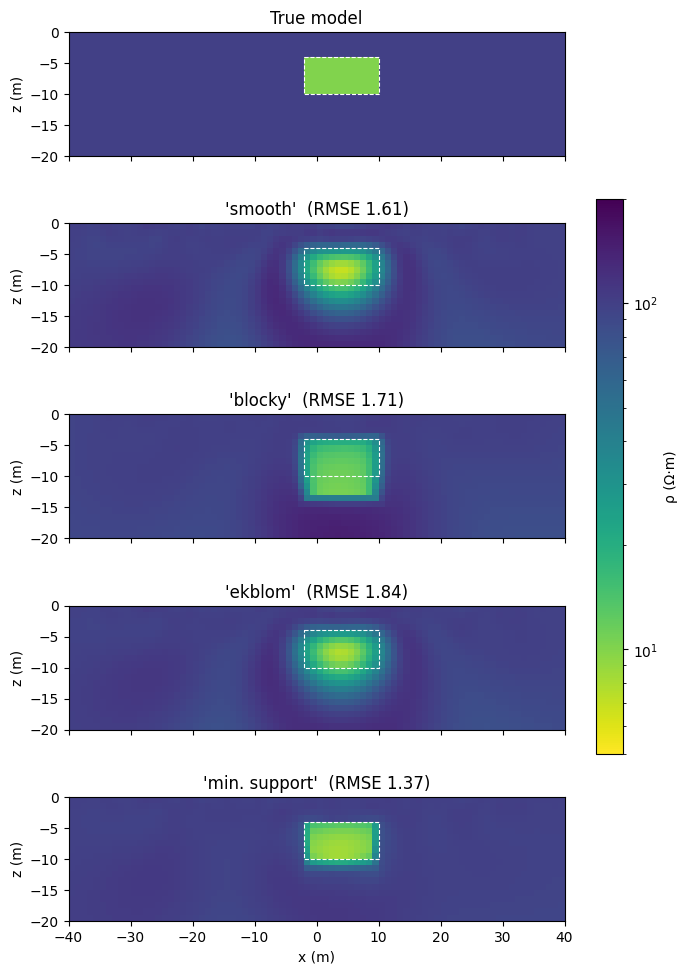

In [5]:
fig, axs = plt.subplots(5, 1, figsize=(8, 12), sharex=True)
plot_model(axs[0], sigma_true, 'True model')
for ax, st in zip(axs[1:], smooth_types):
    im = plot_model(ax, results[st]['sigma'], f"'{st}'  (RMSE {results[st]['rms'][-1]:.2f})")
axs[-1].set_xlabel('x (m)')
fig.colorbar(im, ax=axs, label='ρ (Ω·m)', shrink=0.6)
plt.show()

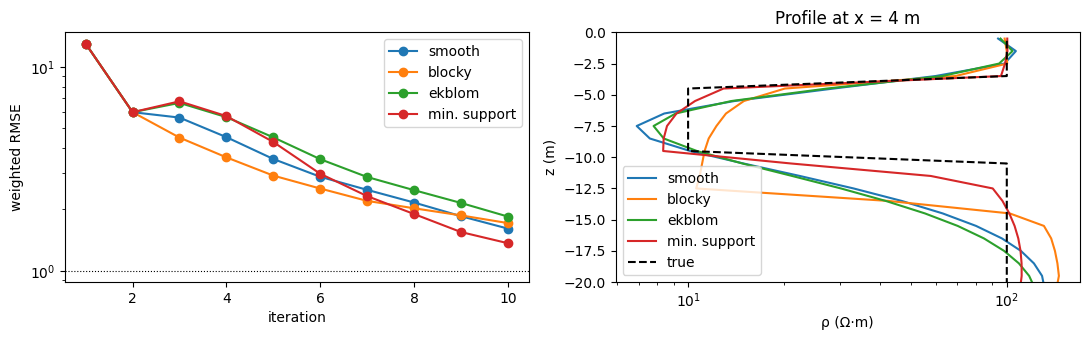

               median |log10(ρ/ρ_true)|   block   background
smooth                                 0.189    0.029
blocky                                 0.177    0.020
ekblom                                 0.210    0.026
min. support                           0.057    0.012


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for st in smooth_types:
    axs[0].plot(np.arange(1, 11), results[st]['rms'], 'o-', label=st)
axs[0].axhline(1.0, color='k', lw=0.8, ls=':')
axs[0].set_xlabel('iteration')
axs[0].set_ylabel('weighted RMSE')
axs[0].set_yscale('log')
axs[0].legend()

# vertical resistivity profile through the centre of the block
ix = np.argmin(np.abs(g.fv.xc - 4.0))
for st in smooth_types:
    r = (1 / results[st]['sigma']).reshape(g.fv.nz, g.fv.nx)[:, ix]
    axs[1].semilogx(r, g.fv.zc, label=st)
axs[1].semilogx((1 / sigma_true).reshape(g.fv.nz, g.fv.nx)[:, ix], g.fv.zc, 'k--', label='true')
axs[1].set_ylim(-20, 0)
axs[1].set_xlabel('ρ (Ω·m)')
axs[1].set_ylabel('z (m)')
axs[1].set_title('Profile at x = 4 m')
axs[1].legend()
plt.tight_layout()
plt.show()

roi = (np.abs(xc) < 40) & (zc > -20)
print(f"{'':13s}  median |log10(ρ/ρ_true)|   block   background")
for st in smooth_types:
    s = results[st]['sigma']
    err = np.abs(np.log10(s / sigma_true))
    print(f'{st:13s}  {"":22s} {np.median(err[block]):6.3f}   {np.median(err[roi & ~block]):6.3f}')

## IRLS weights of the final models

Weights of the vertical gradient computed by `GridDC.calc_reg` from the final models. With `'blocky'` and
`'min. support'`, small weights at the edges of the block let the model change sharply there, while large
weights in the background keep it flat.

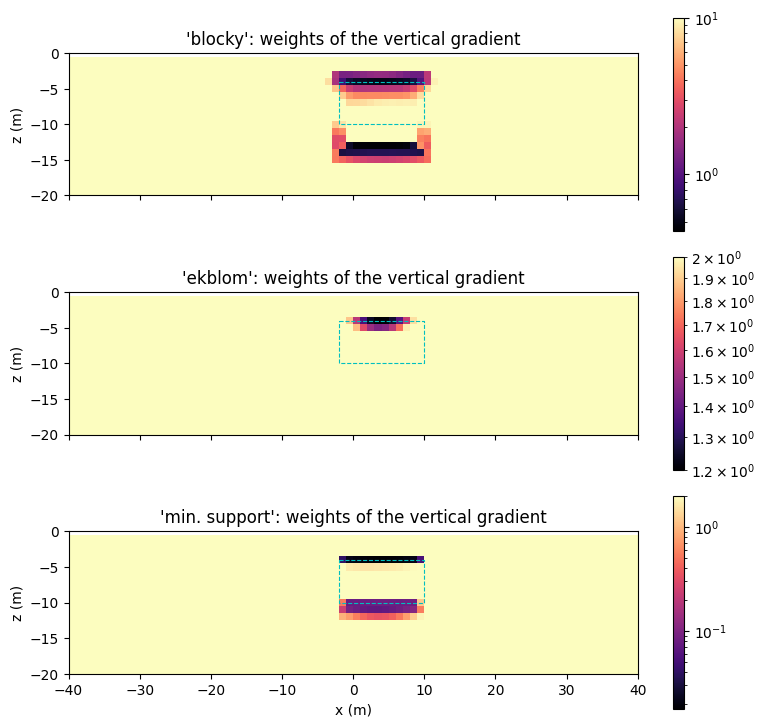

In [7]:
fig, axs = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True)
z_faces = g.fv.z[1:-1]
for ax, st in zip(axs, ('blocky', 'ekblom', 'min. support')):
    res = results[st]
    _, _, _, WGz = res['grid'].calc_reg(np.ones(g.fv.nc), res['inv'], np.log(res['sigma']), 0.0,
                                        None, None, None, np.arange(g.fv.nc))
    im = ax.pcolormesh(g.fv.xc, z_faces, WGz.reshape(g.fv.nz - 1, g.fv.nx), norm=LogNorm(), cmap='magma')
    ax.plot(*outline['xy'], 'c--', lw=0.8)
    ax.set_xlim(-40, 40)
    ax.set_ylim(-20, 0)
    ax.set_aspect('equal')
    ax.set_title(f"'{st}': weights of the vertical gradient")
    ax.set_ylabel('z (m)')
    fig.colorbar(im, ax=ax)
axs[-1].set_xlabel('x (m)')
plt.tight_layout()
plt.show()

## Remarks

- `'smooth'` spreads the anomaly over a larger region, with a contrast that is too strong at its centre (about 7 Ω·m
  instead of 10 Ω·m at x = 4 m) and too weak near its edges.
- `'blocky'` ($L_1$) produces a piecewise constant model with sharp, mostly horizontal and vertical boundaries, but it
  places the base of the block too deep.
- `'min. support'` gives the most compact body here, with a resistivity close to the true value.
- `'ekblom'` with $p = 1$ and $\epsilon = 0.05$ stays close to `'smooth'` because of the cap of 2 on its weights:
  with gradients of $\ln\sigma$ smaller than about 0.5 per metre, the weights are at the cap (see the weights above).
  Smaller caps or other values of $p$ and $\epsilon$ change this behaviour.
- With all types of regularization, the base of the block is poorly resolved (sensitivity decreases with depth).
- The weights are recomputed from the current model at each iteration, so they only act from the third model on
  (the RMSE curves are identical for the first two iterations).
- The final misfit depends on the regularization: with the same $\beta$ schedule, the schemes do not reach the same
  RMSE. A fair comparison at equal misfit would require tuning $\beta$ for each scheme.